In [5]:
#Importing Librarries
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [6]:
# Load Dataset
df = pd.read_csv("../data/raw/online_retail_II.csv")

In [7]:
df.shape

(1067371, 8)

In [8]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [9]:
# Removing time from Invoice_Date
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'],errors='coerce')

In [10]:
# Calculating Total Price
df['TotalPrice']=df['Quantity']*df['Price']

In [11]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
TotalPrice          0
dtype: int64

In [12]:
df=df.dropna(subset=['Customer ID','InvoiceDate'])

In [13]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
TotalPrice     0
dtype: int64

In [14]:
df=df.drop_duplicates()

In [15]:
#Summary 
print("Date Range:",df['InvoiceDate'].min(),"to",df['InvoiceDate'].max())
print("Unique Customers:",df['Customer ID'].nunique())
print("Unique Products:",df['StockCode'].nunique())

Date Range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique Customers: 5942
Unique Products: 4646


In [17]:
#Exploratory Data Analysis
# we will use to visualise missing values in dataset
!pip install missingno

In [18]:
import missingno as msno

<Axes: >

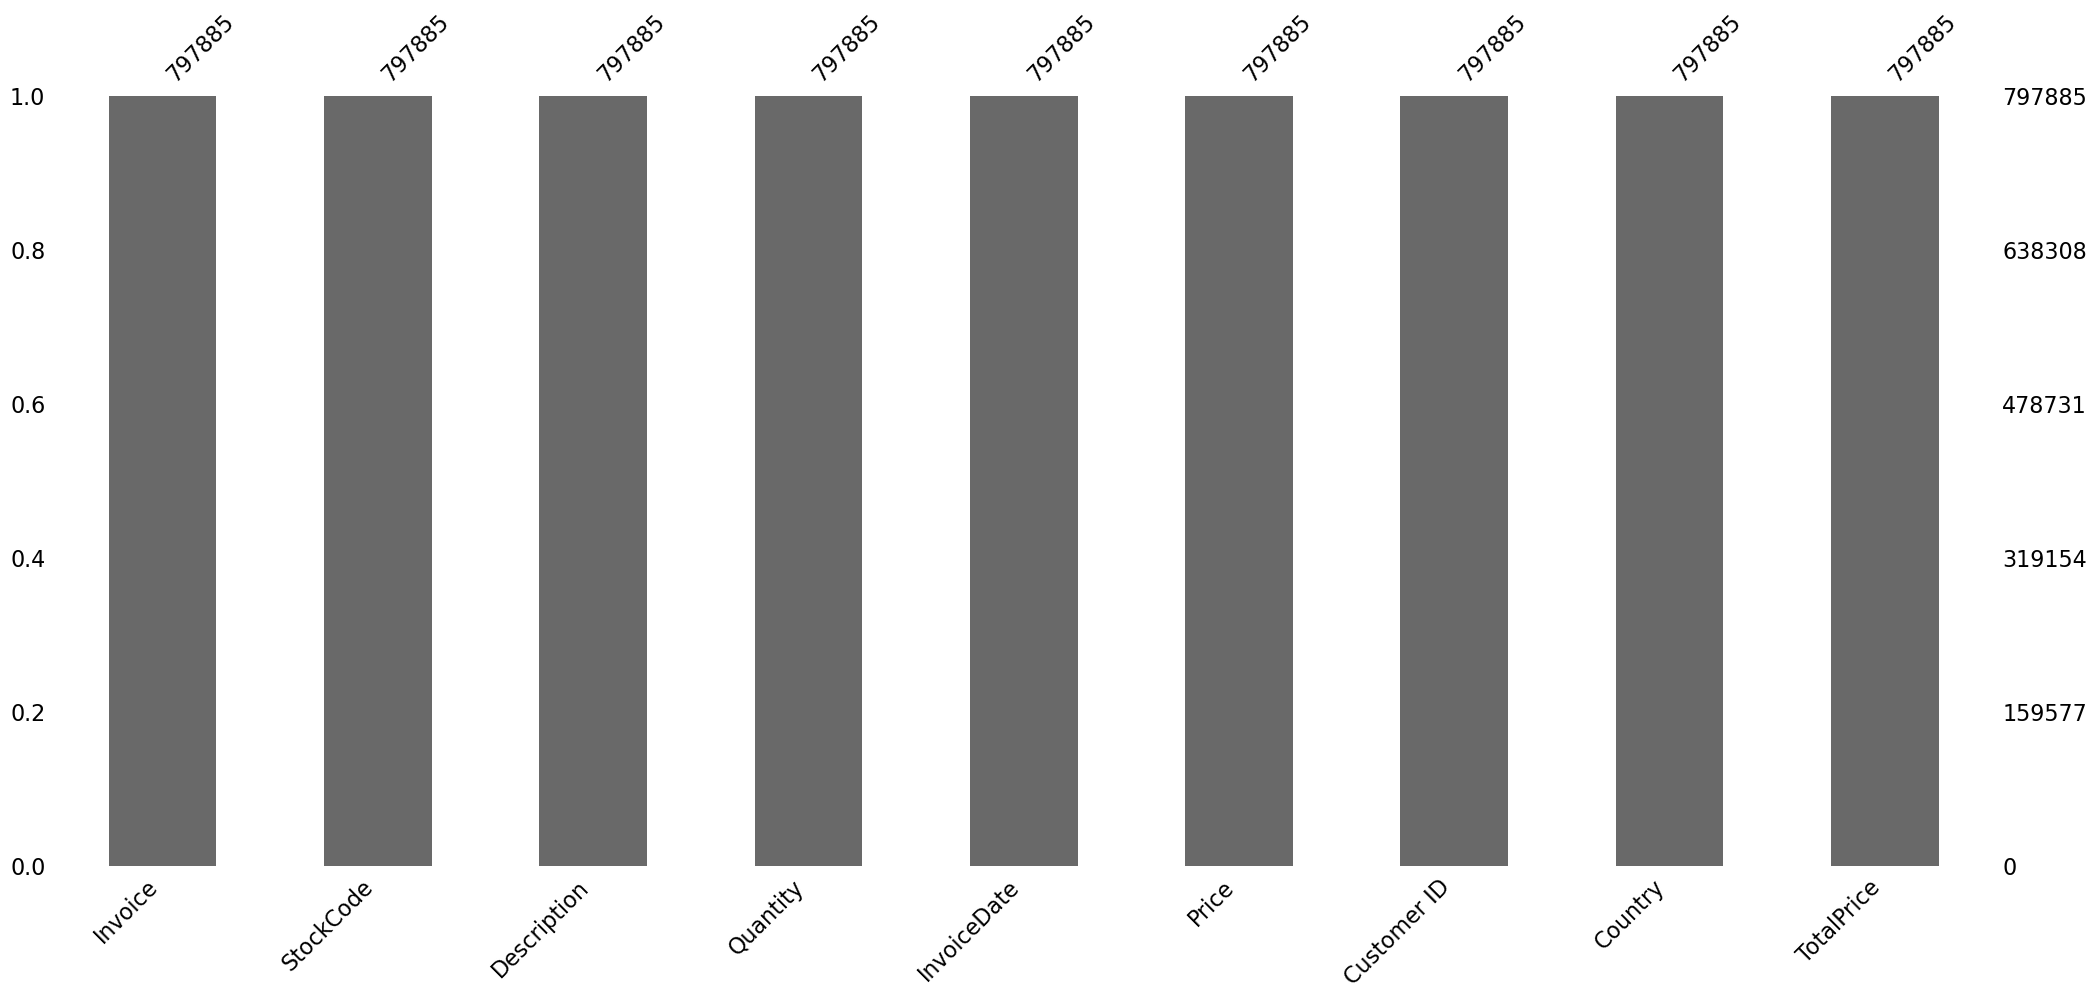

In [19]:
msno.bar(df)

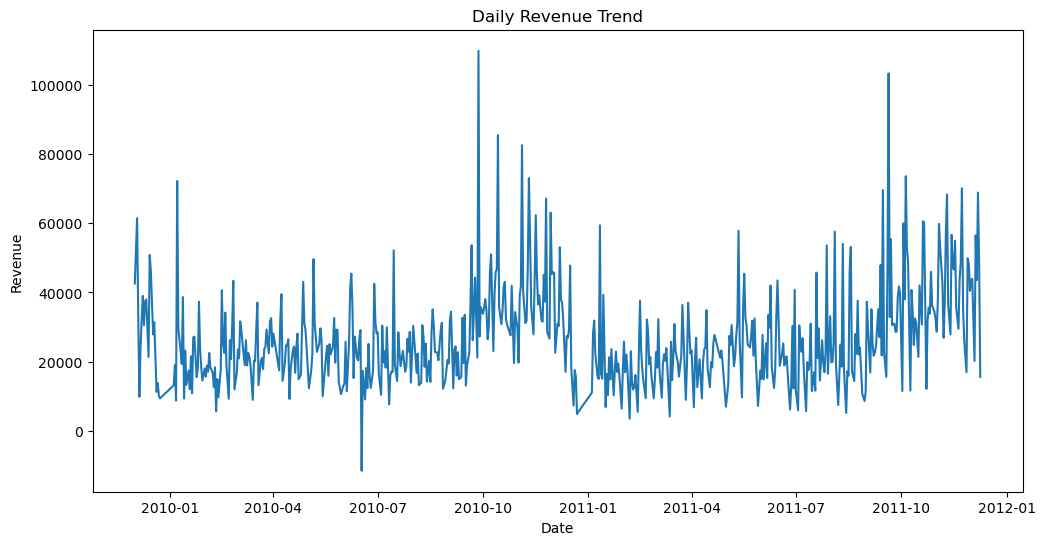

In [20]:
daily_sales=df.groupby(df['InvoiceDate'].dt.date)['TotalPrice'].sum()
plt.figure(figsize=(12,6))
daily_sales.plot()
plt.title("Daily Revenue Trend")
plt.ylabel("Revenue")
plt.xlabel("Date")
plt.show()

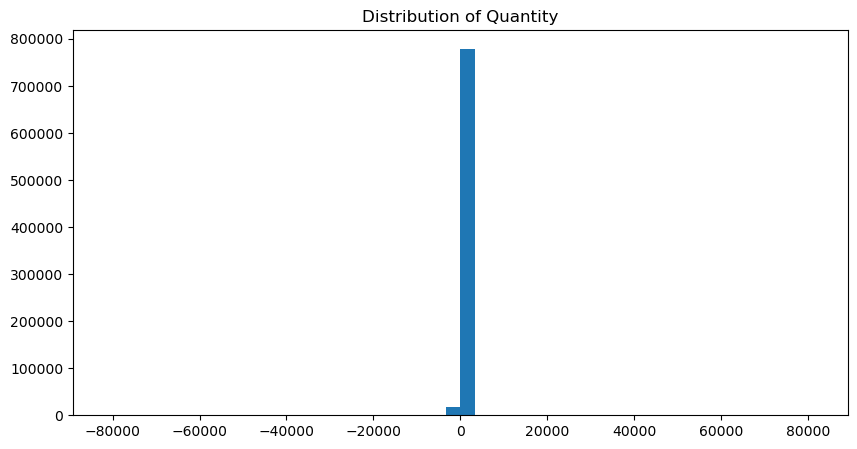

In [27]:
plt.figure(figsize=(10,5))
plt.hist(df['Quantity'].dropna(), bins=50)
plt.title("Distribution of Quantity")
plt.show()

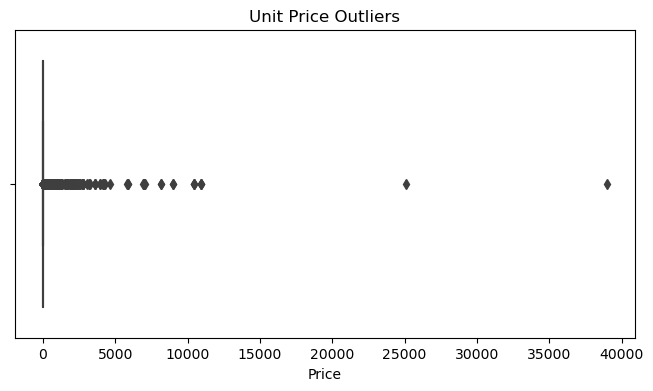

In [22]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Price'])
plt.title("Unit Price Outliers")
plt.show()

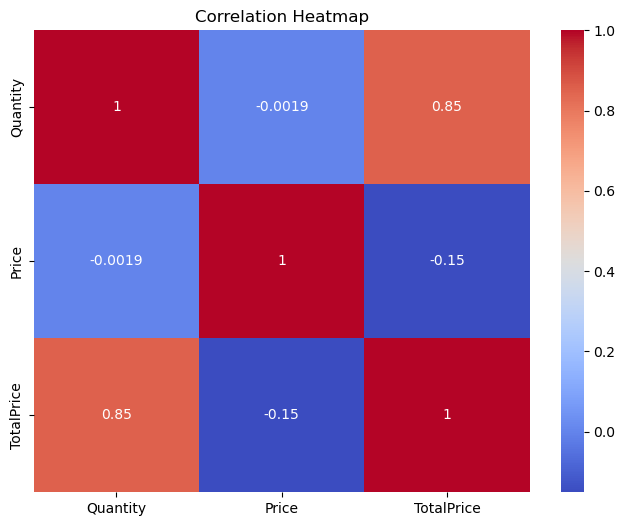

In [23]:
plt.figure(figsize=(8,6))
sns.heatmap(df[['Quantity','Price','TotalPrice']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [24]:
# Feature Engineering 
# We will aggregate daily sales here.
daily_sales=df.groupby(df['InvoiceDate'].dt.date)['TotalPrice'].sum().reset_index()
daily_sales.columns=['Date','Revenue']

In [25]:
daily_sales['Rolling7']=daily_sales['Revenue'].rolling(7).mean()
daily_sales['Rolling30']=daily_sales['Revenue'].rolling(30).mean()

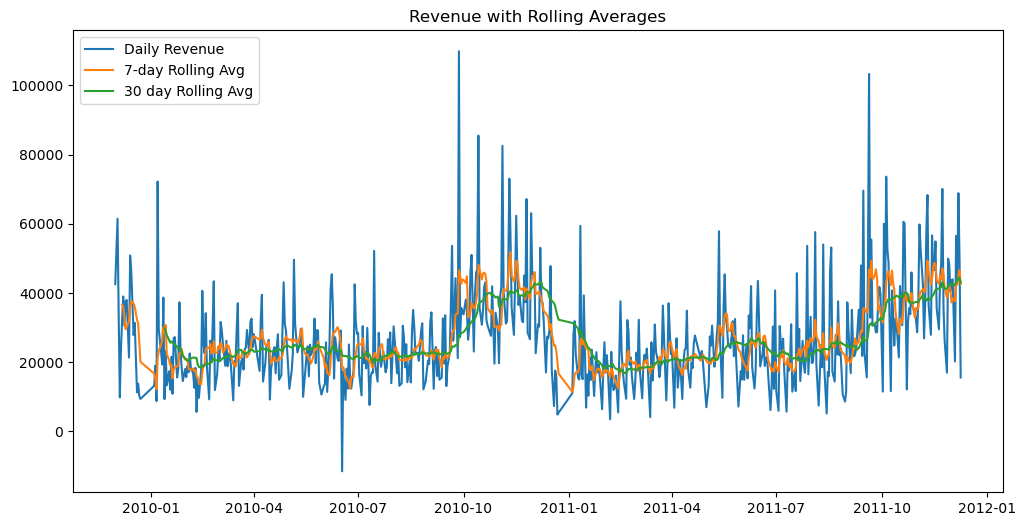

In [26]:
plt.figure(figsize=(12,6))
plt.plot(daily_sales['Date'],daily_sales['Revenue'],label="Daily Revenue")
plt.plot(daily_sales['Date'],daily_sales['Rolling7'],label="7-day Rolling Avg")
plt.plot(daily_sales['Date'],daily_sales['Rolling30'],label="30 day Rolling Avg")
plt.legend()
plt.title("Revenue with Rolling Averages")
plt.show()

In [28]:
daily_sales.to_csv("../data/processed/daily_sales.csv", index=False)